In [1]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 100 * us

n_rc=10
n_input_rows = n_rc  
n_input_columns = n_rc 
n_output_rows = n_rc  
n_output_columns = n_rc 
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -60. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.1 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 3. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5.7 * nS 
g_AMPA_rec_E = 5.7 * nS 
g_AMPA_ext_I = 5.7 * nS
g_AMPA_rec_I = 5.7 * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms



#STDP/iSTDP
Apre   =  0.0025
Apost  = -0.0030
w_max = 1.0 #1.5

Apre_i  = -0.0010
Apost_i =  0.0012
w_max_i = 1.0


tau_HSP = 100*second           
target_rate = 2.0*Hz            
record_dt = 200*ms

tau_vm = 10*second
tau_active = 10*second
  

center_neurons = [14, 24,34, 44, 54, 64,89]
recurrent_radius = 3


kill_mask = np.ones(100, dtype=np.float32)
# kill_mask[np.array([range(45,47),range(35,37),range(55,57)]).flatten()]=0
# pen_idx = np.concatenate([range(24,28),[34,38,44,48,54,58],range(41,68)])
# far_idx = np.concatenate([range(1,18),range(71,99)])

# kill_mask[range(32,37)]=0 
# pen_idx = np.concatenate([range(21,28),[31,38],range(41,48)])
# far_idx = np.concatenate([range(1,18),range(71,99)])

kill_mask[np.array([range(42,47),range(32,37)]).flatten()]=0
pen_idx = np.concatenate([range(21,28),[31,38,41,48],range(51,58)])
far_idx = np.concatenate([range(1,18),range(71,99)])

core_idx = np.where(kill_mask == 0)[0]          


def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA):
    # variables
    n_input_rows = 10  
    n_input_columns = 10 
    n_output_rows = 10 
    n_output_columns = 10 
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn ) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E  * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * k_AMPA_E_hsp  * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E * k_GABA_E_hsp * (v - V_I) * s_GABA     : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     : 1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dk_AMPA_E_hsp/dt = ((1 - k_AMPA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_ins_AMPA_E
                - (k_AMPA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_int_AMPA_E) : 1

    dk_GABA_E_hsp/dt = (-(k_GABA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_int_GABA_E
                + (1 - k_GABA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * 0.3 * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * 0.3 * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz


    dy_act / dt = -y_act / tau_active : 1
    '''


    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_E, method='euler')
    P_E.v = V_L
    P_E.k_AMPA_E_hsp = 0.35  
    P_E.k_GABA_E_hsp = 0.35  
    P_E.tau_ins_AMPA_E = tau_ins_AMPA   #50'000
    P_E.tau_int_AMPA_E = tau_int_AMPA   #5'000
    P_E.tau_ins_GABA_E = tau_ins_GABA   
    P_E.tau_int_GABA_E = tau_int_GABA  

    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler')
    P_I.v = V_L


    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    
    C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre = '''
        s_AMPA_ext += w  
        ''', method='euler', name='PG_E')
    C_PG_E.connect(j='i')  

    
    C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre = '''
        s_AMPA += w  
        ''', method='euler', name='E_E')
    recurrent_radius = 2
    for y1 in range(n_output_rows):
        for x1 in range(n_output_columns):
            post = y1 * n_output_columns + x1
            for dy in range(-recurrent_radius, recurrent_radius + 1):
                for dx in range(-recurrent_radius, recurrent_radius + 1):
                    if dx == 0 and dy == 0:
                        continue
                    x2 = x1 + dx
                    y2 = y1 + dy
                    if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                        pre = y2 * n_output_columns + x2
                        C_E_E.connect(i=pre, j=post)
    C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
    s_AMPA += w
    ''', method='euler', name='E_I') #        x_postE_post += 1.0 
    C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
    for inh_idx, (ix, iy) in enumerate(inh_positions):
        for ex_y in range(n_output_rows):
            for ex_x in range(n_output_columns):
                if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                    exc_idx = ex_y * n_output_columns + ex_x
                    C_I_E.connect(i=inh_idx, j=exc_idx)
                    C_E_I.connect(i=exc_idx, j=inh_idx)
    C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
    for iy in range(n_inh_rows):
        for ix in range(n_inh_cols):
            post = iy * n_inh_cols + ix
            for dy in range(-1, 2):
                for dx in range(-1, 2):
                    if dx == 0 and dy == 0:
                        continue
                    x2, y2 = ix + dx, iy + dy
                    if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                        pre = y2 * n_inh_cols + x2
                        C_I_I.connect(i=pre, j=post)



    C_PG_E.w[:] = 1.2 #np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
    C_I_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
    C_I_I.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
    C_E_I.w[:] = 0.6#np.clip(np.random.normal(loc=0.40, scale=0.05, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I
    C_E_E.w[:] = np.clip(np.random.normal(loc=0.44, scale=0.05, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', 
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    
    rate_container_E = NeuronGroup(1, 'r_pop_E : Hz', method='euler')
    C_rE = Synapses(P_E, rate_container_E,
                model='r_pop_E_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rE.connect()

    rate_container_I = NeuronGroup(1, 'r_pop_I : Hz', method='euler')
    C_rI = Synapses(P_I, rate_container_I,
                model='r_pop_I_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rI.connect()

    rate_core = NeuronGroup(1, 'r_core : Hz', method='euler', name='rate_core')
    rate_pen  = NeuronGroup(1, 'r_pen  : Hz', method='euler', name='rate_pen')
    rate_far  = NeuronGroup(1, 'r_far  : Hz', method='euler', name='rate_far')
    # Core
    C_r_core = Synapses(
        P_E, rate_core,
        model=''' N_core : 1
        r_core_post = r_est_pre / N_core : Hz (summed)''',
        method='euler',
        name='C_r_core'
    )
    C_r_core.connect(i=core_idx, j=0)
    C_r_core.N_core = len(core_idx)
    # Penumbra
    C_r_pen = Synapses(
        P_E, rate_pen,
        model='''N_pen : 1
        r_pen_post = r_est_pre / N_pen : Hz (summed)''',
        method='euler',
        name='C_r_pen'
    )
    C_r_pen.connect(i=pen_idx, j=0)
    C_r_pen.N_pen= len(pen_idx)
    # Far
    C_r_far = Synapses(
        P_E, rate_far,
        model='''N_far : 1
        r_far_post = r_est_pre / N_far : Hz (summed)''',
        method='euler',
        name='C_r_far'
    )
    C_r_far.connect(i=far_idx, j=0)
    C_r_far.N_far=len(far_idx)
    
    rate_core_mon = StateMonitor(rate_core, 'r_core', record=True, dt=record_dt, name='rate_core_mon')
    rate_pen_mon  = StateMonitor(rate_pen,  'r_pen',  record=True, dt=record_dt, name='rate_pen_mon')
    rate_far_mon  = StateMonitor(rate_far,  'r_far',  record=True, dt=record_dt, name='rate_far_mon')
    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=record_dt, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=record_dt, name='act_mon_I')
    
    rate_pop_mon_E = StateMonitor(rate_container_E, 'r_pop_E', record=True, dt=record_dt, name='rate_pop_mon_E')
    rate_pop_mon_I = StateMonitor(rate_container_I, 'r_pop_I', record=True, dt=record_dt, name='rate_pop_mon_I')

    gAMPA_mon_E = StateMonitor(P_E, 'k_AMPA_E_hsp', record=True, dt=record_dt, name='k_AMPA_E_hsp')
    gGABA_mon_E = StateMonitor(P_E, 'k_GABA_E_hsp', record=True, dt=record_dt, name='k_GABA_E_hsp')

    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')


    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



def show_rand_rate(net, show_time = 1000*ms):
    N_inp=net['inp'].N
    rates = np.random.normal(loc=40, scale=3, size=N_inp)
    rates *= kill_mask
    rate_img = np.clip(rates, 5, 50)*Hz
    net['inp'].rates = rate_img
    net.run(show_time, report = 'text')



def run_sim(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA,show_time = 1000*ms):
    net = build_network(tau_ins_AMPA=tau_ins_AMPA,tau_int_AMPA=tau_int_AMPA,tau_ins_GABA=tau_ins_GABA,tau_int_GABA=tau_int_GABA)
    show_rand_rate(net,show_time=show_time)
    return net



INFO       Cache size for target 'cython': 2272 MB.
You can call clear_cache('cython') to delete all files from the cache or manually delete files in the '/home/vincent/.cython/brian_extensions' directory. [brian2]


INFO:root:creating /tmp/brian_flag_test_eebkl16l/tmp
INFO:root:creating /tmp/brian_flag_test_eebkl16l/tmp/brian_flag_test_eebkl16l
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_eebkl16l/flag_test.cpp -o /tmp/brian_flag_test_eebkl16l/tmp/brian_flag_test_eebkl16l/flag_test.o -w
INFO:root:creating /tmp/brian_flag_test_igwbvl98/tmp
INFO:root:creating /tmp/brian_flag_test_igwbvl98/tmp/brian_flag_test_igwbvl98
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_igwbvl98/flag_test.cpp -o /tmp/brian_flag_test_igwbvl98/tmp/brian_flag_test_igwbvl98/flag_test.o -O3
INFO:root:creating /tmp/brian_flag_test_ydjvh3zx/tmp
INFO:root:creating /tmp/brian_flag_test_ydjvh3zx/tmp/brian_flag_test_ydjvh3zx
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_ydjvh3zx/flag_test.cpp -o /tmp/brian_flag_test_yd

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s


WARNING    'rates' is an internal variable of group 'inp', but also exists in the run namespace with the value array([39.16856458, 43.36154689, 38.38745856, ..., 45.64848087,
       45.30097992, 43.98192967]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Starting simulation at t=0. s for a duration of 20. ks
125.359 s (0%) simulated in 10s, estimated 26m 25s remaining.
266.834 s (1%) simulated in 20s, estimated 24m 39s remaining.
0.413923 ks (2%) simulated in 30s, estimated 23m 40s remaining.
0.560337 ks (2%) simulated in 40s, estimated 23m 8s remaining.
0.699929 ks (3%) simulated in 50s, estimated 22m 59s remaining.
0.847429 ks (4%) simulated in 1m 0s, estimated 22m 36s remaining.
0.993225 ks (4%) simulated in 1m 10s, estimated 22m 20s remaining.
1.147247 ks (5%) simulated in 1m 20s, estimated 21m 55s remaining.
1.296767 ks (6%) simulated in 1m 30s, estimated 21m 38s remaining.
1.442365 ks (7%) simulated in 1m 40s, estimated 21m 27s remaining.
1.582897 ks (7%) simulated in 1m 50s, estimated 21m 20s remaining.
1.731053 ks (8%) simulated in 2m 0s, estimated 21m 6s remaining.
1.863986 ks (9%) simulated in 2m 10s, estimated 21m 5s remaining.
1.996567 ks (9%) simulated in 2m 20s, estimated 21m 2s remaining.
2.145132 ks (10%) simulated in 2

WARNING    /home/vincent/bmnn/lib/python3.12/site-packages/brian2tools/plotting/data.py:59: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)
 [py.warnings]
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)



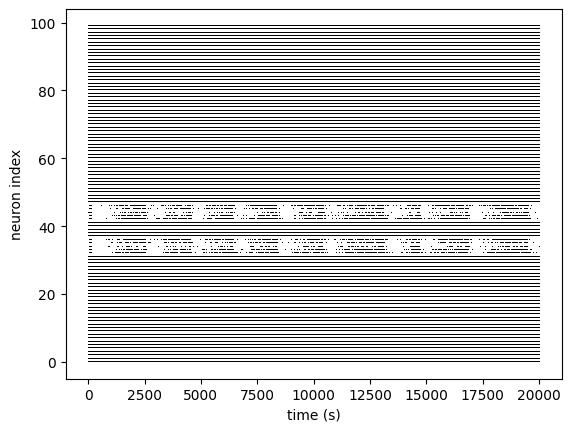

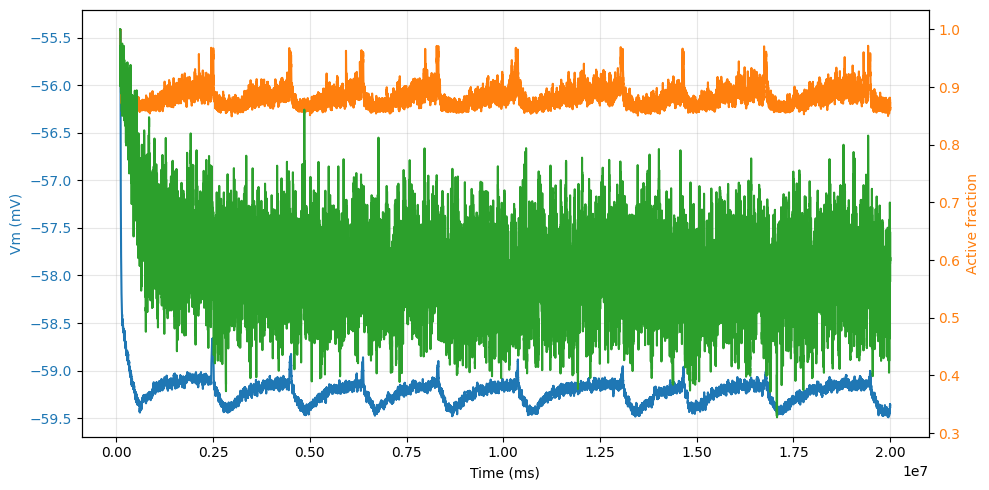

In [2]:
start_scope()
defaultclock.dt = 1000 * us
net = run_sim(tau_ins_AMPA=500*second,
              tau_int_AMPA=500*second,
              tau_ins_GABA=500*second,
              tau_int_GABA=500*second,
              show_time=20000*second)

V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')


fig, ax1 = plt.subplots(figsize=(10,5))

ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

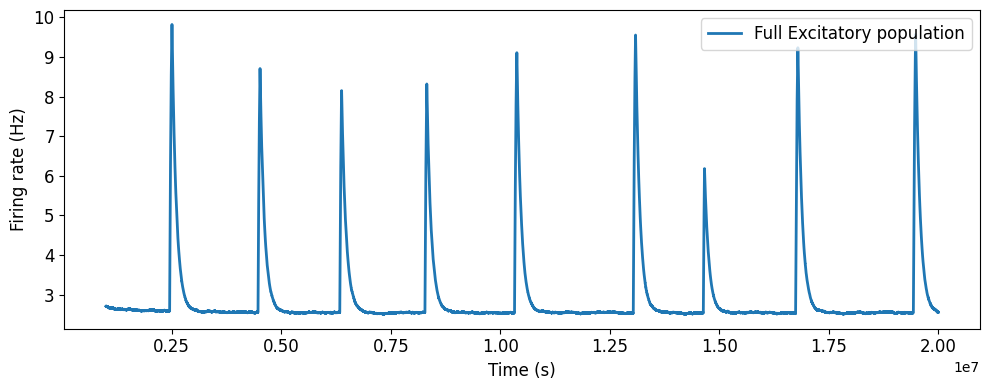

In [4]:
r_est_E = net['rate_pop_mon_E']  
r_est_E_core = net['rate_core_mon']  
r_est_E_pen = net['rate_pen_mon']  
r_est_E_far = net['rate_far_mon']  


plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[5000:]/ms, r_est_E.r_pop_E[0,5000:]/Hz, color='tab:blue',linewidth=2, label='Full Excitatory population')
# plt.plot(r_est_E_core.t[500:]/ms, r_est_E_core.r_core[0,500:]/Hz, color='red',linewidth=2,linestyle=':', label='Core')
# plt.plot(r_est_E_pen.t[500:]/ms, r_est_E_pen.r_pen[0,500:]/Hz, color='tab:orange',linewidth=2,linestyle='--', label='Penumbra')
# plt.plot(r_est_E_far.t[500:]/ms, r_est_E_far.r_far[0,500:]/Hz, color='tab:green',linewidth=2,linestyle='-.', label='Far from core')
plt.xlabel('Time (s)', fontsize =12)
plt.ylabel('Firing rate (Hz)',fontsize =12)
plt.tick_params(axis='both', labelsize=12)
plt.legend(loc=1,fontsize=12)
plt.tight_layout()

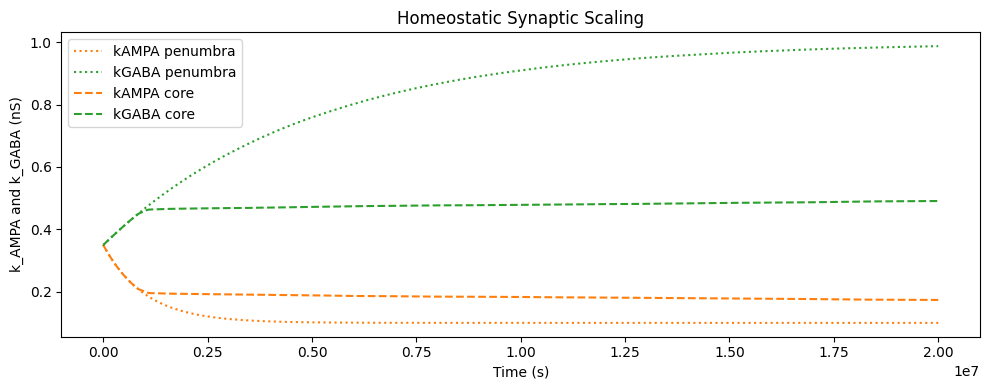

In [103]:
kAMPA_mon_E=net['k_AMPA_E_hsp']
kGABA_mon_E=net['k_GABA_E_hsp']

plt.figure(figsize=(10, 4))
plt.plot(kAMPA_mon_E.t/ms, kAMPA_mon_E.k_AMPA_E_hsp[45], label='kAMPA penumbra',color='tab:orange',linestyle=':')
plt.plot(kGABA_mon_E.t/ms, kGABA_mon_E.k_GABA_E_hsp[45], label='kGABA penumbra',color='tab:green',linestyle=':')
plt.plot(kAMPA_mon_E.t/ms, kAMPA_mon_E.k_AMPA_E_hsp[35], label='kAMPA core',color='tab:orange',linestyle='--')
plt.plot(kGABA_mon_E.t/ms, kGABA_mon_E.k_GABA_E_hsp[35], label='kGABA core',color='tab:green',linestyle='--')
plt.xlabel('Time (s)')
plt.ylabel('k_AMPA and k_GABA (nS)')
plt.title('Homeostatic Synaptic Scaling')
plt.legend()
plt.tight_layout()

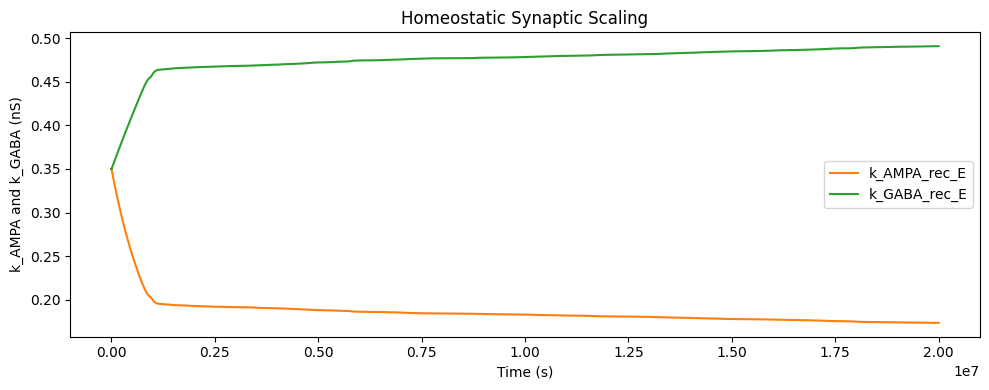

In [104]:
kAMPA_mon_E=net['k_AMPA_E_hsp']
kGABA_mon_E=net['k_GABA_E_hsp']

plt.figure(figsize=(10, 4))
plt.plot(kAMPA_mon_E.t/ms, kAMPA_mon_E.k_AMPA_E_hsp[35], label='k_AMPA_rec_E',color='tab:orange')
plt.plot(kGABA_mon_E.t/ms, kGABA_mon_E.k_GABA_E_hsp[35], label='k_GABA_rec_E',color='tab:green')
plt.xlabel('Time (s)')
plt.ylabel('k_AMPA and k_GABA (nS)')
plt.title('Homeostatic Synaptic Scaling')
plt.legend()
plt.tight_layout()

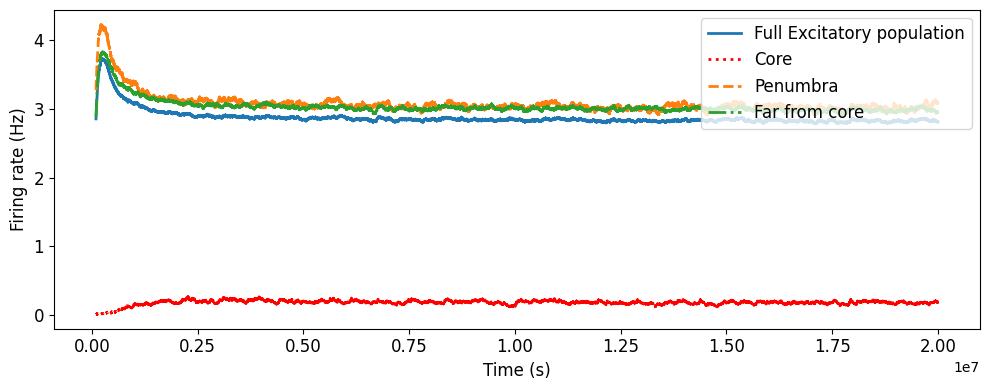

In [7]:
r_est_E = net['rate_pop_mon_E']  
r_est_E_core = net['rate_core_mon']  
r_est_E_pen = net['rate_pen_mon']  
r_est_E_far = net['rate_far_mon']  


plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[500:]/ms, r_est_E.r_pop_E[0,500:]/Hz, color='tab:blue',linewidth=2, label='Full Excitatory population')
plt.plot(r_est_E_core.t[500:]/ms, r_est_E_core.r_core[0,500:]/Hz, color='red',linewidth=2,linestyle=':', label='Core')
plt.plot(r_est_E_pen.t[500:]/ms, r_est_E_pen.r_pen[0,500:]/Hz, color='tab:orange',linewidth=2,linestyle='--', label='Penumbra')
plt.plot(r_est_E_far.t[500:]/ms, r_est_E_far.r_far[0,500:]/Hz, color='tab:green',linewidth=2,linestyle='-.', label='Far from core')
plt.xlabel('Time (s)', fontsize =12)
plt.ylabel('Firing rate (Hz)',fontsize =12)
plt.tick_params(axis='both', labelsize=12)
plt.legend(loc=1,fontsize=12)
plt.tight_layout()

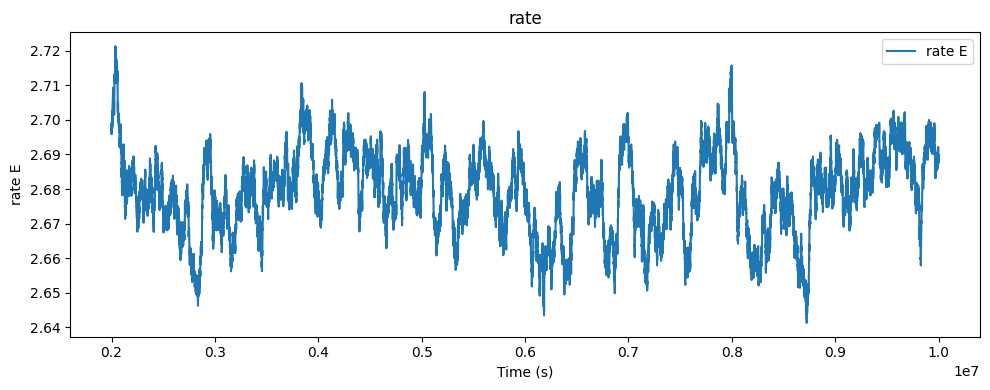

In [114]:
r_est_E = net['rate_pop_mon_E']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[10000:]/ms, r_est_E.r_pop_E[0,10000:]/Hz, color='tab:blue', label='rate E')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()

<Axes: xlabel='time (s)', ylabel='neuron index'>

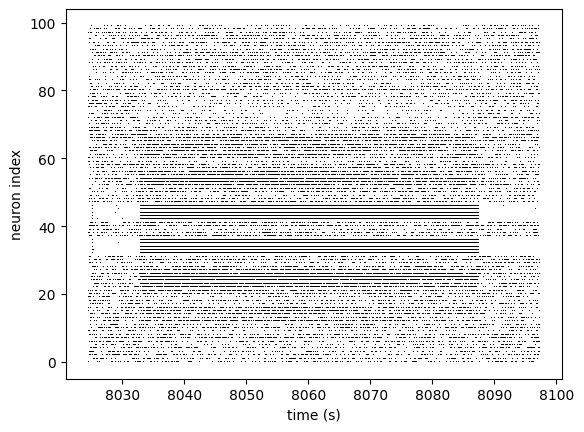

In [12]:
plot_raster(spE.i[int(2.685*10**6):int(2.82*10**6)], spE.t[int(2.685*10**6):int(2.82*10**6)], time_unit=second, marker=',', color='k')

Longer TC for longer period of high risk

In [2]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 100 * us

n_rc=10
n_input_rows = n_rc  
n_input_columns = n_rc 
n_output_rows = n_rc  
n_output_columns = n_rc 
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -60. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.1 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 3. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5.7 * nS 
g_AMPA_rec_E = 5.7 * nS 
g_AMPA_ext_I = 5.7 * nS
g_AMPA_rec_I = 5.7 * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms



#STDP/iSTDP
Apre   =  0.0025
Apost  = -0.0030
w_max = 1.0 #1.5

Apre_i  = -0.0010
Apost_i =  0.0012
w_max_i = 1.0


tau_HSP = 100*second           
target_rate = 2.0*Hz            
record_dt = 200*ms

tau_vm = 10*second
tau_active = 10*second
  

center_neurons = [14, 24,34, 44, 54, 64,89]
recurrent_radius = 3


kill_mask = np.ones(100, dtype=np.float32)
#kill_mask[range(40,47)]=0 #yes
#kill_mask[np.array([range(40,47),range(21,28)]).flatten()]=0 #yes
kill_mask[np.array([range(42,47),range(32,37)]).flatten()]=0



def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA):
    # variables
    n_input_rows = 10  
    n_input_columns = 10 
    n_output_rows = 10 
    n_output_columns = 10 
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn ) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E  * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * k_AMPA_E_hsp  * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E * k_GABA_E_hsp * (v - V_I) * s_GABA     : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     : 1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dk_AMPA_E_hsp/dt = ((1 - k_AMPA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_ins_AMPA_E
                - (k_AMPA_E_hsp - 0.1) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_int_AMPA_E) : 1

    dk_GABA_E_hsp/dt = (-(k_GABA_E_hsp - 0.1) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_int_GABA_E
                + (1 - k_GABA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * 0.3 * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * 0.3 * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz


    dy_act / dt = -y_act / tau_active : 1
    '''


    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_E, method='euler')
    P_E.v = V_L
    P_E.k_AMPA_E_hsp = 0.3  
    P_E.k_GABA_E_hsp = 0.3  
    P_E.tau_ins_AMPA_E = tau_ins_AMPA   #50'000
    P_E.tau_int_AMPA_E = tau_int_AMPA   #5'000
    P_E.tau_ins_GABA_E = tau_ins_GABA   
    P_E.tau_int_GABA_E = tau_int_GABA  

    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler')
    P_I.v = V_L


    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    
    C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre = '''
        s_AMPA_ext += w  
        ''', method='euler', name='PG_E')
    C_PG_E.connect(j='i')  

    
    C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre = '''
        s_AMPA += w  
        ''', method='euler', name='E_E')
    recurrent_radius = 2
    for y1 in range(n_output_rows):
        for x1 in range(n_output_columns):
            post = y1 * n_output_columns + x1
            for dy in range(-recurrent_radius, recurrent_radius + 1):
                for dx in range(-recurrent_radius, recurrent_radius + 1):
                    if dx == 0 and dy == 0:
                        continue
                    x2 = x1 + dx
                    y2 = y1 + dy
                    if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                        pre = y2 * n_output_columns + x2
                        C_E_E.connect(i=pre, j=post)
    C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
    s_AMPA += w
    ''', method='euler', name='E_I') #        x_postE_post += 1.0 
    C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
    for inh_idx, (ix, iy) in enumerate(inh_positions):
        for ex_y in range(n_output_rows):
            for ex_x in range(n_output_columns):
                if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                    exc_idx = ex_y * n_output_columns + ex_x
                    C_I_E.connect(i=inh_idx, j=exc_idx)
                    C_E_I.connect(i=exc_idx, j=inh_idx)
    C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
    for iy in range(n_inh_rows):
        for ix in range(n_inh_cols):
            post = iy * n_inh_cols + ix
            for dy in range(-1, 2):
                for dx in range(-1, 2):
                    if dx == 0 and dy == 0:
                        continue
                    x2, y2 = ix + dx, iy + dy
                    if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                        pre = y2 * n_inh_cols + x2
                        C_I_I.connect(i=pre, j=post)



    C_PG_E.w[:] = 1.2 #np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
    C_I_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
    C_I_I.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
    C_E_I.w[:] = 0.6#np.clip(np.random.normal(loc=0.40, scale=0.05, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I
    C_E_E.w[:] = np.clip(np.random.normal(loc=0.44, scale=0.05, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', 
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    
    rate_container_E = NeuronGroup(1, 'r_pop_E : Hz', method='euler')
    C_rE = Synapses(P_E, rate_container_E,
                model='r_pop_E_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rE.connect()

    rate_container_I = NeuronGroup(1, 'r_pop_I : Hz', method='euler')
    C_rI = Synapses(P_I, rate_container_I,
                model='r_pop_I_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rI.connect()

    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=record_dt, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=record_dt, name='act_mon_I')
    
    rate_pop_mon_E = StateMonitor(rate_container_E, 'r_pop_E', record=True, dt=record_dt, name='rate_pop_mon_E')
    rate_pop_mon_I = StateMonitor(rate_container_I, 'r_pop_I', record=True, dt=record_dt, name='rate_pop_mon_I')

    gAMPA_mon_E = StateMonitor(P_E, 'k_AMPA_E_hsp', record=True, dt=record_dt, name='k_AMPA_E_hsp')
    gGABA_mon_E = StateMonitor(P_E, 'k_GABA_E_hsp', record=True, dt=record_dt, name='k_GABA_E_hsp')

    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')


    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



def show_rand_rate(net, show_time = 1000*ms):
    N_inp=net['inp'].N
    rates = np.random.normal(loc=40, scale=3, size=N_inp)
    rates *= kill_mask
    rate_img = np.clip(rates, 5, 50)*Hz
    net['inp'].rates = rate_img
    net.run(show_time, report = 'text')



def run_sim(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA,show_time = 1000*ms):
    net = build_network(tau_ins_AMPA=tau_ins_AMPA,tau_int_AMPA=tau_int_AMPA,tau_ins_GABA=tau_ins_GABA,tau_int_GABA=tau_int_GABA)
    show_rand_rate(net,show_time=show_time)
    return net



INFO       Cache size for target 'cython': 2263 MB.
You can call clear_cache('cython') to delete all files from the cache or manually delete files in the '/home/vincent/.cython/brian_extensions' directory. [brian2]


INFO:root:building '_cython_magic_223c4c15e78747f6d120aa10763c2149' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_223c4c15e78747f6d120aa10763c2149.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_223c4c15e78747f6d120aa10763c2149.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_223c4c15e78747f6d120aa10763c2149.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s


WARNING    'rates' is an internal variable of group 'inp', but also exists in the run namespace with the value array([42.28075524, 37.6088083 , 38.44725842, ..., 43.69089803,
       33.4527238 , 40.29958434]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Starting simulation at t=0. s for a duration of 20. ks
132.461 s (0%) simulated in 10s, estimated 25m 0s remaining.
280.444 s (1%) simulated in 20s, estimated 23m 26s remaining.
0.418683 ks (2%) simulated in 30s, estimated 23m 23s remaining.
0.56137 ks (2%) simulated in 40s, estimated 23m 5s remaining.
0.709852 ks (3%) simulated in 50s, estimated 22m 39s remaining.
0.848271 ks (4%) simulated in 1m 0s, estimated 22m 48s remaining.
0.992034 ks (4%) simulated in 1m 10s, estimated 22m 32s remaining.
1.140533 ks (5%) simulated in 1m 20s, estimated 22m 12s remaining.
1.290388 ks (6%) simulated in 1m 30s, estimated 21m 53s remaining.
1.423171 ks (7%) simulated in 1m 40s, estimated 21m 53s remaining.
1.569843 ks (7%) simulated in 1m 50s, estimated 21m 38s remaining.
1.717613 ks (8%) simulated in 2m 0s, estimated 21m 23s remaining.
1.849291 ks (9%) simulated in 2m 10s, estimated 21m 22s remaining.
1.998255 ks (9%) simulated in 2m 20s, estimated 21m 6s remaining.
2.147716 ks (10%) simulated in 2

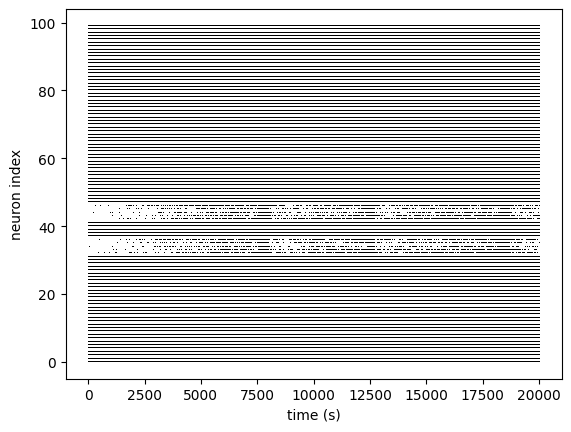

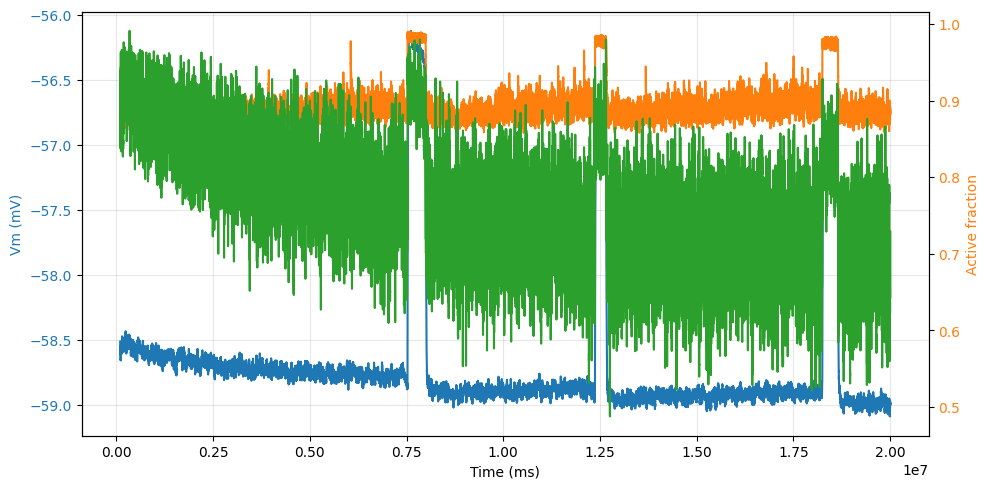

In [16]:
start_scope()
defaultclock.dt = 1000 * us
seed(1)
net = run_sim(tau_ins_AMPA=5000*second,
              tau_int_AMPA=5000*second,
              tau_ins_GABA=5000*second,
              tau_int_GABA=5000*second,
              show_time=20000*second)


V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')


fig, ax1 = plt.subplots(figsize=(10,5))

ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

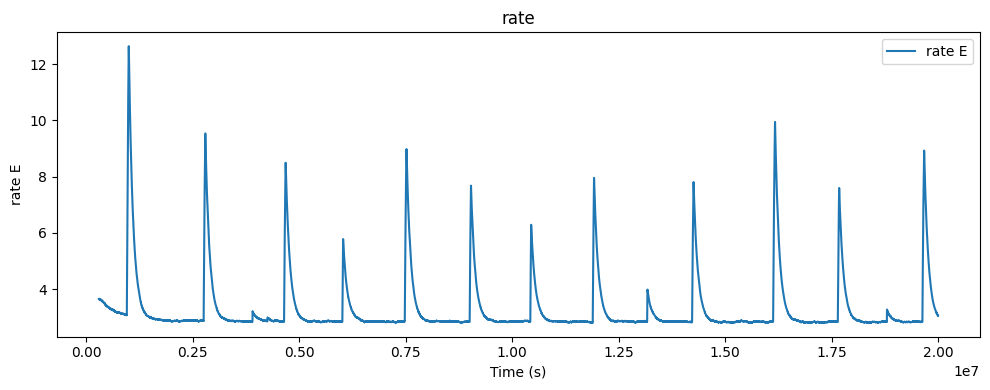

In [ ]:
#r_est_E_500 = net['rate_pop_mon_E']  
#r_est_E_50 = net['rate_pop_mon_E']  
#r_est_E_100 = net['rate_pop_mon_E']  
#r_est_E_100_2 = net['rate_pop_mon_E']  



#r_est_I = net['rate_pop_mon_I']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E_500.t[1500:]/ms, r_est_E_500.r_pop_E[0,1500:]/Hz, color='tab:blue', label='rate E')
#plt.plot(r_est_E_100_2.t[1500:]/ms, r_est_E_100_2.r_pop_E[0,1500:]/Hz, color='tab:red',linestyle=':', label='rate E')

plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()

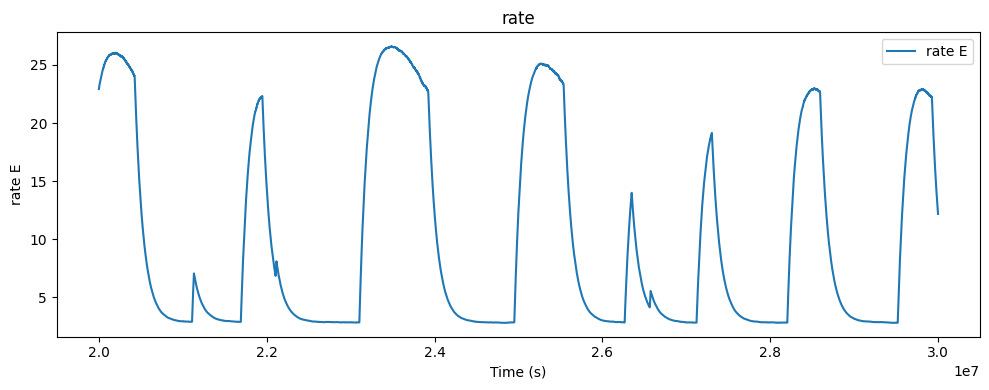

In [11]:
r_est_E = net['rate_pop_mon_E']  
r_est_I = net['rate_pop_mon_I']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[100000:150000]/ms, r_est_E.r_pop_E[0,100000:150000]/Hz, color='tab:blue', label='rate E')
#plt.plot(r_est_I.t[500:]/ms, r_est_I.r_pop_I[0,500:]/Hz, color='tab:green', label='rate I')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()

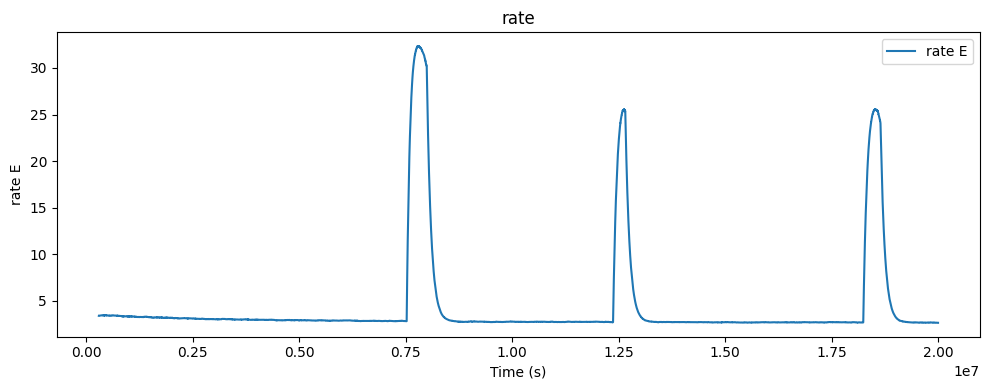

In [17]:
r_est_E_5000 = net['rate_pop_mon_E']  
#r_est_I = net['rate_pop_mon_I']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E_5000.t[1500:]/ms, r_est_E_5000.r_pop_E[0,1500:]/Hz, color='tab:blue', label='rate E')
#plt.plot(r_est_I.t[500:]/ms, r_est_I.r_pop_I[0,500:]/Hz, color='tab:green', label='rate I')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()

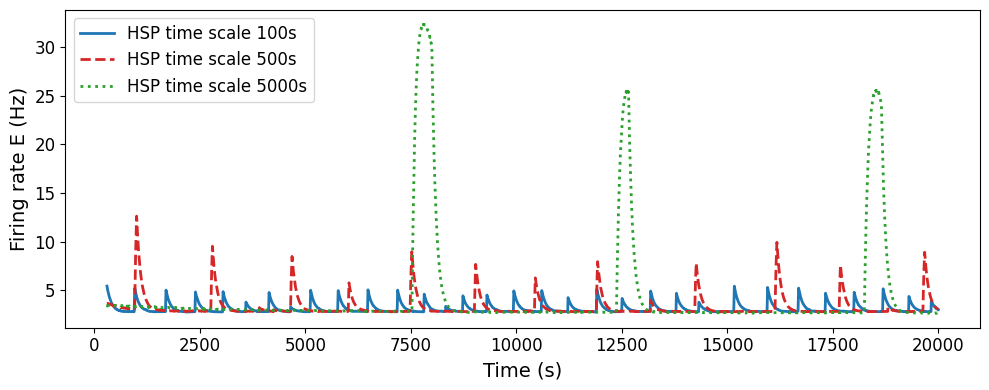

In [18]:
r_5000=r_est_E_5000.r_pop_E[0,1500:]/Hz
#r_50=r_est_E_50.r_pop_E[0,1500:]/Hz
r_100=r_est_E_100.r_pop_E[0,1500:]/Hz
r_t=r_est_E_500.t[1500:]/second
r_500=r_est_E_500.r_pop_E[0,1500:]/Hz
plt.figure(figsize=(10, 4))
plt.plot(r_t, r_100, color='tab:blue', label='HSP time scale 100s',linewidth=2)
plt.plot(r_t,r_500, color='tab:red',linestyle='--', label='HSP time scale 500s',linewidth=2)
plt.plot(r_t,r_5000, color='tab:green',linestyle=':', label='HSP time scale 5000s',linewidth=2)
plt.xlabel('Time (s)', fontsize=14)
plt.ylabel('Firing rate E (Hz)', fontsize=14)
plt.tick_params(axis='both', labelsize=12)
plt.legend(fontsize=12)
plt.tight_layout()

In [31]:
len(r_500)

88500

In [22]:
len(r_5000[101500:200000])

98500